In [1]:
from pathlib import Path
import sys
from IPython.display import HTML, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src/catalogiq').is_dir() and (p / 'notebooks').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the CatalogIQ repository.')
sys.path.insert(0, str(ROOT / 'notebooks'))
from catalogiq_review_support import Review, STYLE, table
from catalogiq_review_visuals import VisualReview, VISUAL_STYLE
display(HTML(STYLE + VISUAL_STYLE))
review = Review(ROOT)
visuals = VisualReview(review)

<div class="cq-heading"><div class="cq-kicker">CatalogIQ · Sprint 1 → current · Ravi · 01 / 09</div>

<h1>Make manual classification the exception.</h1>

<p>Propose consistent labels, accept routine cases under a validated policy, and focus human effort on uncertain predictions. This operating workflow remains proposed.</p></div>

In [2]:
visuals.problem()

<details class="cq-presenter-notes">
<summary>Presenter notes · 70s</summary>

> Start with Ravi’s operational problem: people should not need to classify every listing from scratch. The intended benefit is to propose consistent CatalogIQ labels, allow routine cases through a validated acceptance policy, and concentrate human attention on uncertain or flagged cases. This is the intended workflow, not functionality delivered in this sprint. Routing, acceptance thresholds, reviewer workload, time savings and ROI remain unmeasured or unvalidated. The project covers six labels; five have trained MiniLM candidates, with Platform reserved for simpler methods. From Sprint 1 foundations to today, our result is an auditable basis for choosing an approach. MiniLM is one candidate alongside classical methods and Brand lookup; no definitive solution has been selected.

Evidence: [Project scope](../README.md); [five-target exports](../docs/findings/03_modeling/14_minilm_prediction_exports.md); [modeling scope](../docs/findings/03_modeling/04_target_development_allocation_20261029.md).

</details>

<div class="cq-heading"><div class="cq-kicker">CatalogIQ · Sprint 1 → current · Ravi · 02 / 09</div>

<h1>Research exposed competing taxonomies.</h1>

<p>Retailer categories and curated labels encode different business boundaries.</p></div>

In [3]:
visuals.taxonomy()

<details class="cq-presenter-notes">
<summary>Presenter notes · 85s</summary>

> This is a real validation listing: Jarrow Formulas Fem-Dophilus. The retailer breadcrumb includes Vitamins, Minerals & Supplements, while the supplied CatalogIQ Segment is Digestive Health. The retailer card displays the complete saved ProductCategory breadcrumb. This is why more training alone cannot resolve every disagreement. Maria’s relationship and evaluation research helped distinguish taxonomy hypotheses from confirmed rules. Early assumptions about a strict Segment/Sub-Segment tree and Brand-to-manufacturer assignment did not become current policy. Some Sub-Segments have shared parents; age is an attribute; Platform is sparse. We preserve supplied Mnfr rather than infer J&J from Brand. ProductBrand is explicitly authorized for raw-to-curated Brand normalization. Take unresolved category boundaries to Ravi rather than silently relabeling them. Official numbered sprint boundaries are unavailable; the appendix uses dated milestones.

Evidence: [Current decisions](../docs/decisions.md); [research progression](../docs/findings/01_cleaning/01_CatalogIQ_Pre_Aryx_Findings.md); original real-product example in the retained evidence appendix. Record ID `06d2ca12999a801a09e50c57c1d86d38aeb17aa4a46e419dcbee516450bc63b0`.

</details>

<div class="cq-heading"><div class="cq-kicker">CatalogIQ · Sprint 1 → current · Ravi · 03 / 09</div>

<h1>Preserve useful products. Isolate broken records.</h1>

<p>Conservative cleaning retains usable listings and records every approved correction. Uncertain fields do not justify discarding an entire product.</p></div>

In [4]:
visuals.cleaning()

<details class="cq-presenter-notes">
<summary>Presenter notes · 95s</summary>

> The original sources contain 84,552 training listings and 28,082 prediction-input listings, 32 columns each. Original missingness was substantial: Platform 98.69%, ProductDescription 67.75%, ProductContents 60.13%; those are the historical profile’s convention and denominator. A successful CSV parse did not establish structural alignment. Current integrated cleaning retains 83,938 training rows and quarantines 614, plus 27,870 retained prediction-input rows and 212 quarantined. No review holds remain under the current policy. Keep otherwise usable Exclude rows; missing targets affect that target’s supervision. Quarantine missing name/description/contents or corroborated displacement, without guessing repairs. The Vicks VapoRub example is a real approved edit: Cold / Flu to Cold/Flu. Only seven label edits were approved: four slash-spacing and three Other Lifestyle replacements. Sebastian owns target/structural work; Max contributed feature decisions and integration; Maria independently audited cleaning. Complete partition tables and before/after examples remain in the appendix.

Evidence: [Original profile](../docs/findings/00_data_profile/01_profile_results.md); [current policy validation](../docs/findings/01_cleaning/05_current_policy_validation.md); [decision authority](../docs/decisions.md).

</details>

<div class="cq-heading"><div class="cq-kicker">CatalogIQ · Sprint 1 → current · Ravi · 04 / 09</div>

<h1>Split families, not individual listings.</h1>

<p>Shared product groups and exact-input controls reduce leakage. The protected test remains isolated while development continues on approved training and validation populations.</p></div>

In [5]:
visuals.splitting()

<details class="cq-presenter-notes">
<summary>Presenter notes · 90s</summary>

> No reliable canonical product key was established from UPC, SKU, MDM ID or names. Sebastian’s frozen V4 workflow groups product-only evidence and identical effective four-field 128-token inputs, then keeps whole groups within partitions. Labels do not drive grouping. Counts are all rows: 59,111 training, 12,667 validation, 12,160 protected test. Family dots are illustrative glyphs, not sampled products or proportional counts. The protected test reserves eligible previously unscored families rather than padding to 15% with exposed records. The later five-field 256-token audit found zero identical-input crossings; that result does not imply zero semantic leakage. The lexical audit still found 223 crossing candidates, and copied descriptions/known misses remain. Brand and Sub-Segment use approved development allocations with the same frozen groups and protected test. Today’s notebook reads protected identity metadata only, never test.csv or protected labels. Full caveats are retained in the appendix.

Evidence: [Split finalization](../docs/findings/02_splitting/02_finalization_20261009.md); [256-token equality audit](../docs/findings/03_modeling/02_minilm_256_equality_audit_20261015.md); [target allocations](../docs/findings/03_modeling/04_target_development_allocation_20261029.md).

</details>

<div class="cq-heading"><div class="cq-kicker">CatalogIQ · Sprint 1 → current · Ravi · 05 / 09</div>

<h1>Simple baselines earned their place.</h1>

<p>Category information improved the classical baseline. MiniLM added validation performance, but operating cost, class coverage, and business priorities still determine the choice.</p></div>

In [6]:
visuals.baseline()

<details class="cq-presenter-notes">
<summary>Presenter notes · 90s</summary>

> Max’s word unigram/bigram TF-IDF plus logistic regression is a credible, simple comparison: vocabulary and IDF fit on training only, C=1, no class weights. Four product fields achieve 83.90% macro-F1; concatenating ProductCategory achieves 91.00%, on the same 11,952 labeled Segment validation records. Category reduces errors from 1,246 to 667; Lifestyle CHC drops slightly, so the gain is not universal. Five-field MiniLM achieves 94.4490% macro-F1, about 3.45 points above the reported five-field classical result. Original classical prediction files are absent locally: those rounded values come from Max’s committed verified report. The neural value is independently recomputed from saved predictions. Maria’s earlier V3 LinearSVC is not directly comparable. Her later Segment harness analyses are separate documented work, not the final all-target comparison. Timing scopes differ, so we do not claim a cost ratio. All original baseline charts and tables remain in the appendix.

Evidence: [Classical results](../docs/findings/03_modeling/02_classical_segment_results_20261010.md); [classical implementation](../docs/findings/03_modeling/01_classical_segment_baseline.md); [MiniLM representation](../docs/findings/03_modeling/01_minilm_256_reproducibility_20261015.md).

</details>

<div class="cq-heading"><div class="cq-kicker">CatalogIQ · Sprint 1 → current · Ravi · 06 / 09</div>

<h1>One recipe. Five separate models.</h1>

<p>Shared inputs and fixed training settings make comparisons traceable; each target retains its approved development population.</p></div>

In [7]:
visuals.architecture()

<details class="cq-presenter-notes">
<summary>Presenter notes · 80s</summary>

> Five models are fine-tuned separately; the diagram shows the architecture repeated for each target. Sebastian’s shared workflow uses sentence-transformers/all-MiniLM-L6-v2 at the pinned revision: six encoder layers, 12 attention heads, hidden size 384. Category is prefixed to ProductName, ProductBrand, ProductDescription and ProductContents; cleaned field markers form one combined sequence capped at 256 tokens. Category can displace later text. Attention-mask mean pooling feeds dropout 0.10 and a target-specific linear head. Encoder and head are fine-tuned. Three fixed epochs and the final third-epoch checkpoint avoid picking a favorable validation epoch. AdamW uses learning rate 3e-5, weight decay 0.01, 10% warmup; FP32, batches 32/64, seed 42. IDs, URLs, retailer-name feature, timestamps, provenance and other target labels are excluded. The frozen grouping contract remains 128 tokens. Mnfr’s declared class-weighting comparison selected the unweighted checkpoint: four errors versus five, a one-record difference. Model-family selection remains open.

Evidence: [Verified architecture and settings](../docs/findings/03_modeling/01_minilm_256_reproducibility_20261015.md); [Mnfr selection](../docs/findings/03_modeling/11_mnfr_minilm_selection_20261029.md); [remaining targets](../docs/findings/03_modeling/13_remaining_minilm_training_20261029.md).

</details>

<div class="cq-heading"><div class="cq-kicker">CatalogIQ · Sprint 1 → current · Ravi · 07 / 09</div>

<h1>Five targets trained. Coverage remains uneven.</h1>

<p>High accuracy can hide weak classes. Sub-Segment needs particular scrutiny, and missing validation support limits claims about rare labels.</p></div>

In [8]:
visuals.results()

<details class="cq-presenter-notes">
<summary>Presenter notes · 100s</summary>

> All five selected experiment checkpoints have verified saved validation predictions, with metrics recalculated here. Segment accuracy is 96.95%, full macro-F1 94.45%; Mnfr 99.97% and 99.57%; age 99.75% and 98.74%; Brand 96.66% and 87.83%; Sub-Segment 88.58% and 65.73%. Each row has its own eligible population; this is not a cross-target ranking. Full-vocabulary macro-F1 retains training classes with zero validation support: five Brand classes and two Sub-Segment classes. The observed-label convention gives Brand 91.02% and Sub-Segment 68.52% on the same predictions; both conventions remain in the appendix. External Upper Respiratory recall is only 2/23 despite precision 1.0. Mnfr correctly identifies 237/238 J&J records, so it is not merely majority-class prediction. Rare-class support, taxonomy conflicts, uncalibrated probabilities and one-seed limitations remain. This is validation evidence, not protected-test or production performance. Maria’s final comparative evaluation is ongoing.

Evidence: [Five-target exports and conventions](../docs/findings/03_modeling/14_minilm_prediction_exports.md); [per-class limitations](../docs/findings/03_modeling/13_remaining_minilm_training_20261029.md); complete recomputed results and class tables in the retained appendix.

</details>

<div class="cq-heading"><div class="cq-kicker">CatalogIQ · Sprint 1 → current · Ravi · 08 / 09</div>

<h1>Brand has no universal winner.</h1>

<p>MiniLM leads on overall accuracy; the lookup leads on balanced class performance. Choose according to the cost of errors, not a single headline.</p></div>

In [9]:
visuals.brand()

<details class="cq-presenter-notes">
<summary>Presenter notes · 90s</summary>

> This compares MiniLM with the original deterministic Brand lookup, not the later probabilistic variant. Both use the same 58,888 labeled training and 12,619 validation records; all catch-all labels and missing/unseen feature cases remain in the score. ProductBrand is authorized for normalization. The lookup uses training-majority label per normalized key; missing/unseen keys fall back to the training-majority UnItemised brand. MiniLM accuracy is 96.6638% versus 95.6494%; lookup full-vocabulary macro-F1 is 93.1191% versus MiniLM 87.8344%. MiniLM handles Other Brands better: recall 63.43% versus 18.80%. Coverage is 82.84%, and fallback cases remain in headline metrics. The probabilistic lookup, fixed alpha=1 before validation, changes only 17 decisions and is not calibrated; its full results remain intact in the appendix. The real Astepro error there shows that high neural softmax confidence can accompany a wrong label. We have not built a hybrid or selected a winner.

Evidence: [Original Brand comparison](../docs/findings/03_modeling/13_remaining_minilm_training_20261029.md); [probabilistic variant](../docs/findings/03_modeling/15_brand_probabilistic_lookup.md); real product and cohort tables in the appendix.

</details>

<div class="cq-heading"><div class="cq-kicker">CatalogIQ · Sprint 1 → current · Ravi · 09 / 09</div>

<h1>Choose the operating policy before the model.</h1>

<p>Maria’s final comparison remains ongoing. Agree business priorities and review capacity before model selection and protected-test evaluation.</p></div>

In [10]:
visuals.decisions()

<details class="cq-presenter-notes">
<summary>Presenter notes · 80s</summary>

> Ask Ravi to settle the taxonomy boundaries, acceptable reviewer workload, and which error types matter most. Then Maria can complete the final target-specific comparison, minority/error analysis, calibration and review-policy assessment. Existing checks prove loader compatibility and headline scoring, not that this final review is complete. Segment analyses on Maria’s branch are acknowledged separately in the evidence appendix. A previously completed retailer-transfer diagnostic is also retained: on the same 2,511 non-Amazon validation records, mixed-retailer accuracy is 94.46% versus 87.10% for Amazon-only training. Training volume, assortment, wording and class mix also change, so this is not causal evidence about category dependence. Before deployment, measure safe acceptance share, accepted-case error rate, reviewer time and comparable inference latency. Those business outcomes remain unmeasured. Keep the protected test reserved until the model and procedure are selected. No new training is needed to review the saved predictions; MiniLM remains a candidate.

Evidence: [Prediction handoff](../docs/findings/03_modeling/14_minilm_prediction_exports.md); [retailer-transfer evidence](../docs/references/research/catalogiq_modeling_findings.md); contribution provenance and remaining work in the retained appendix.

</details>

## Appendix — retained evidence and technical detail

The original detailed narrative, charts, tables, calculations, citations and technical appendices are preserved below. They are outside the nine-slide presentation. Presenter notes are collapsed; the offline HTML hides them by default.

The visual slides add the adjacent `catalogiq_review_visuals.py` helper. The original read-only evidence loader and metric calculations are unchanged. In the HTML, use **Appendix** or **A** to open this material; use **Notes** or **N** only when rehearsing.

<div class="cq-kicker">Capstone technical progress / 30 October 2026 / Product owner: Ravi</div>

# CatalogIQ
## From catalog uncertainty to auditable classification

**Sprint 1 foundations → current model and evaluation handoff**

Classify retailer product listings into a consistent CatalogIQ label system, with traceable data preparation and credible evaluation.

<div class="cq-callout"><b>Review outcome:</b> five MiniLM targets trained; validation exports verified; final comparative evaluation and production selection remain open.</div>

**Model selection remains open.** MiniLM is a candidate alongside the classical baseline and Brand lookup; the best approach may differ by target.

**Intended business value:** reduce the listings people must classify from scratch, while focusing their effort on uncertain or flagged predictions.

<div class="cq-flow">
<div><b>Incoming listing</b><br>System proposes CatalogIQ labels</div>
<div><b>Validated acceptance policy</b><br>Routine cases can avoid manual classification</div>
<div><b>Human review</b><br>Uncertain or flagged cases are checked and corrected</div>
</div>

This is the intended operating workflow. Routing and acceptance thresholds remain to be validated; time savings and ROI have **not** been measured.

**13-minute core presentation** · Questions afterward · Implementation and evidence in the appendix

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 35s:** Lead with less manual classification and focused human review as the intended benefit. MiniLM is one candidate; no definitive model or acceptance policy has been chosen. This sprint verifies predictions, while routing and measured savings remain future work. Six labels are in scope; five have MiniLM candidates.

<small>Evidence: [Project scope](../README.md), [five-target exports](../docs/findings/03_modeling/14_minilm_prediction_exports.md), [modeling scope](../docs/findings/03_modeling/04_target_development_allocation_20261029.md).</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 02 of 14</div>

## What the team has delivered

| Phase | Evidence-backed progress | Contributions |
|---|---|---|
| Sprint 1 foundations · September | CatalogIQ scope, dataset profile, taxonomy research and evaluation criteria | Sebastian: profiling and exploration; Maria: relationship and evaluation research; Max: feature checks |
| Data readiness · late September–3 October | Audited target corrections, feature cleaning, independent structural checks and integrated partitions | Sebastian: target/structural work; Max: feature decisions and integration; Maria: independent cleaning audit |
| Shared development · 9–24 October | Frozen group-aware splits; TF-IDF baselines; Segment MiniLM; evaluation harness | Sebastian: split/transformer workflow; Max: classical models and packaging; Maria: harness and Segment comparisons |
| Current handoff · 29–30 October | Five trained targets, approved target allocations, verified prediction exports and Brand lookup comparisons | Sebastian: target-aware training/export workflows; Maria’s cross-target comparative evaluation remains ongoing |

**Why this sequence matters:** trustworthy data and isolated evaluation populations precede model comparison.

<div class="cq-small">Later phases are dated milestones. The repository does not establish official numbered sprint boundaries.</div>

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 45s:** Credit the three different kinds of work: Sebastian’s reproducible modeling pipeline, Max’s cleaning and classical baseline contributions, and Maria’s independent research/audit/evaluation work. Maria has completed Segment analyses on her evaluation branch; that is distinct from a final comparison across all five targets.

<small>Evidence: Git commits `251274d`, `639e009`, `505d309`, `9010a63`, `cd5296a`, `a8fb9d1`, `09df407`, `128d9c7`; Maria branch commits `72502a2`, `cb8e6e2`, `05e52e2`. Details in Appendix C.</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 03 of 14</div>

## Domain research changed the problem definition

| Label / relationship | What the evidence supports | Why we acted on it |
|---|---|---|
| Segment ↔ Sub-Segment | Related labels; observed shared parents undermine a universal strict tree | Preserve labels; do not enforce a global parent whitelist |
| Retailer ProductCategory → curated Segment | Useful supporting evidence, with different category boundaries | Test as a feature; keep taxonomy conflicts visible |
| ProductBrand → curated Brand | Retailer raw-to-curated normalization is explicitly authorized | Include ProductBrand and compare against a training-only lookup |
| Brand → Mnfr | Association does not authorize manufacturer relabeling | Preserve supplied manufacturer values, including missingness |
| TargetAgeGroup | A product attribute, rather than another taxonomy level | Evaluate each age class; do not infer a hierarchy |
| Platform | Extremely sparse labels and limited independent support | Excluded from MiniLM; simpler methods remain future work |

**Research discipline:** early hierarchy/whitelist hypotheses were revised when row-level evidence and current policy disagreed.

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 50s:** Use the probiotic example verbally: a retailer can place it under supplements while CatalogIQ labels it Digestive Health. This is a definition question as well as a prediction task. Do not present historical manufacturer fills or strict hierarchy proposals as accepted rules.

<small>Evidence: [Pre-Aryx findings, with policy warning](../docs/findings/01_cleaning/01_CatalogIQ_Pre_Aryx_Findings.md), [current decisions](../docs/decisions.md), [authorized Brand scope](../docs/findings/03_modeling/13_remaining_minilm_training_20261029.md).</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 04 of 14</div>

## Initial exploration: sparse fields, skewed labels, uncertain identity

**Original exports:** 84,552 training listings + 28,082 prediction-input listings; 32 columns each.

No exact duplicate rows were reported. That did **not** rule out repeated products, variants or copied text. UPC, SKU, MDM ID and product name did not establish a reliable canonical product key.

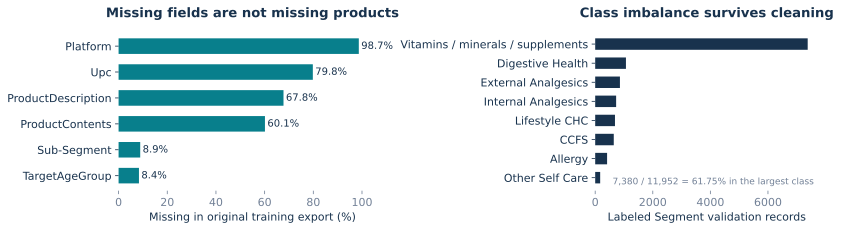

In [11]:
review.profile()

**Why this mattered:** a successful CSV parse did not establish row alignment; missing descriptions alone could not justify discarding useful listings. Class imbalance required macro-F1 and per-class checks alongside accuracy.

<div class="cq-small">Left: original-export profile, using its documented missingness convention. Right: current labeled V4 Segment validation population. Denominators intentionally differ.</div>

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 55s:** Point to Platform’s 98.69% missingness and the 61.75% majority-class baseline. Numeric anchors and target fields contained evidence of shifted content even though the initial field-width scan found no malformed-width rows. We retained listing-level provenance instead of inventing a product key.

<small>Evidence: [Original profile](../docs/findings/00_data_profile/01_profile_results.md), [identity findings](../docs/findings/01_cleaning/01_CatalogIQ_Pre_Aryx_Findings.md), existing development validation records.</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 05 of 14</div>

## Cleaning: correct only what we can justify

**Preserve usable products; quarantine rows with explicit structural evidence.** Feature warnings alone do not make a row unusable.

- Keep otherwise usable rows marked `Exclude`; drop timestamp, Sun1–Sun5 and Notes from modeling views while retaining audit evidence.
- Quarantine when name, description and contents are all absent, or when corroborating fields indicate displacement. Do not guess shifted values back into place.
- Preserve missing targets and supplied Mnfr. Missing labels affect eligibility for that target, rather than forcing whole-row removal.

In [12]:
review.cleaning()

Source,Original rows,Candidate,Quarantine,Review hold
Labeled source,84552,83938,614,0
Prediction-input source,28082,27870,212,0


Source row (1-based),Real development product,Before,After
21582,Vicks VapoRub - Lavender - 1.76oz,Cold / Flu,Cold/Flu
37965,Abreva Docosanol 10% Fever Blister and Cold Sore Treatment .07 oz 2 Pk,Other Lifestyle,Other Lifestyle CHC


**Only seven approved label edits:** four `Cold / Flu → Cold/Flu`; three `Other Lifestyle → Other Lifestyle CHC`. Every change carries source identity and an explicit rule.

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 65s:** Show the two real development products. Slash spacing consolidates the same label; the three reviewed Lifestyle records share the accepted parent. We preserve questionable but usable data because aggressive cleaning can silently change the business population. Candidate means retained, not certified error-free. Exclude retention and timestamp exclusion were group agreements; several structural policies were Sebastian’s documented decisions.

<small>Evidence: [Policy decisions](../docs/decisions.md), [current full-data validation](../docs/findings/01_cleaning/05_current_policy_validation.md), `integrated_policy_v4_final_20261003/{validation.json,label_changes.csv}`. Titles joined only from development records.</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 06 of 14</div>

## Keep product families together; keep the final test closed

**Why a random row split was insufficient:** related listings could put essentially the same product into training and validation.

Frozen V4 groups combine product-only evidence with must-links for identical effective four-field, 128-token inputs. Whole groups stay within a partition; grouping does not use target labels.

In [13]:
review.split_table()

Partition,All rows,Share,Use now
Train,59111,70.42%,Fit models / training-only mappings
Validation,12667,15.09%,Compare development candidates
Protected test,12160,14.49%,Reserved; IDs/groups only in this notebook


**Verified controls:** 52,393 frozen groups; zero group crossings; zero exact four-field payload crossings. The later five-field, 256-token equality audit also found zero identical-input crossings.

**Exposure-aware test reservation:** reserve eligible, previously unscored families; do not pad the test with previously trained/reviewed records just to reach 15%.

**Residual risk remains:** the name audit reported 223 lexical crossing candidates across all records (221 train–validation, two train–test); copied-description crossings and known grouping misses also remain. Exact-input isolation does not establish zero semantic leakage.

**Target-specific development allocations:** Brand and Sub-Segment improve feasible class coverage using the same frozen groups and protected test. Their validation populations differ from Segment’s.

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 70s:** Explain the important distinction: we preserve frozen product groups and the protected test, while approved Brand/Sub-Segment development roles differ. The independent name matches are candidates, not confirmed leakage errors. Today’s notebook reads only protected IDs/groups; the earlier 256-token audit used allowlisted test features and did not read test labels.

<small>Evidence: [Split finalization](../docs/findings/02_splitting/02_finalization_20261009.md), [256-token audit](../docs/findings/03_modeling/02_minilm_256_equality_audit_20261015.md), [target allocation rationale](../docs/findings/03_modeling/04_target_development_allocation_20261029.md).</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 07 of 14</div>

## TF-IDF established a credible baseline; category information helped

**Max’s baseline:** word unigram/bigram TF-IDF → logistic regression (`C=1`, no class weights). Vocabulary and IDF fit on training only; both arms use identical labeled development records.

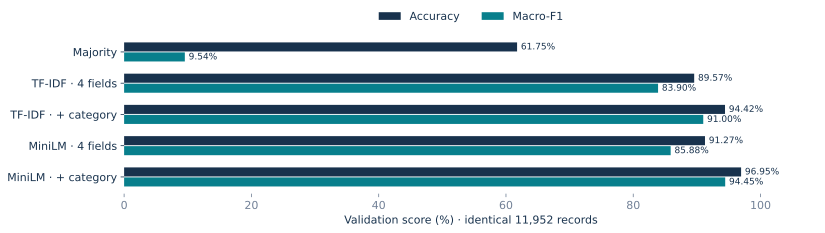

In [14]:
review.baseline()

**Feature finding:** adding ProductCategory reduced classical validation errors from **1,246 to 667**. Lifestyle CHC was an exception: its F1 fell slightly. Category was useful evidence, rather than a universal correction.

**Why keep the simpler model:** it provides a fast, interpretable comparison before accepting the complexity of a contextual encoder. Classical and neural timing scopes differ; no cost ratio is claimed.

<div class="cq-small">TF-IDF/majority scores: committed verified report (macro-F1 rounded there); original classical prediction files are not present locally. MiniLM scores: saved ablation CSV, with the five-field result independently recomputed here. No models are fitted by this notebook.</div>

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 60s:** All five bars concern the same 11,952 Segment validation records. Do not compare Maria’s earlier V3 LinearSVC values with Max’s V4 logistic regression. These are category-concatenation experiments; category-level features were deferred in cleaning. Five-field MiniLM gains about 3.45 macro-F1 percentage points over the reported five-field TF-IDF result.

<small>Evidence: [Verified classical results](../docs/findings/03_modeling/02_classical_segment_results_20261010.md), [classical implementation](../docs/findings/03_modeling/01_classical_segment_baseline.md), `segment_category_ablation_256_20261010/validation_comparison.csv`.</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 08 of 14</div>

## MiniLM: one controlled representation and training recipe

<div class="cq-flow">
<div><b>Five input fields</b><br>Category first, then name, raw brand, description, contents</div>
<div><b>One 256-token sequence</b><br>Field markers, HTML cleanup, character caps, right truncation</div>
<div><b>MiniLM encoder</b><br>6 layers · 12 heads · hidden size 384</div>
<div><b>Task head</b><br>Masked mean pooling → dropout 0.10 → target-specific linear head</div>
</div>

| Controlled choice | Why it was made |
|---|---|
| Fine-tune encoder and head | Learn task-specific decisions from product text, beyond sparse word features |
| Three fixed epochs; final third-epoch checkpoint | Avoid selecting a favorable epoch after observing validation |
| AdamW; learning rate 3e-5; weight decay 0.01; warmup 10% | Reuse the established training recipe rather than conduct a new search |
| Seed 42; FP32; batches 32 / 64; pinned encoder revision | Make inputs, settings and artifact identity traceable |
| Same five-field formatter across targets | Reuse a verified representation while varying head size and approved population |

**Input boundary:** no IDs, URLs, timestamps, retailer-name feature, provenance or other target columns. ProductCategory can displace later text within the combined budget. The frozen grouping contract remains at 128 tokens.

**Mnfr exception tested explicitly:** moderate class weighting `[1,5]` did not improve the declared comparison; the selected handoff uses unweighted cross-entropy.

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 65s:** The encoder is sentence-transformers/all-MiniLM-L6-v2, used with a custom mean-pooled classification head. It is not a prompted LLM. Four-field and five-field Segment arms shared initialization and schedule; there was one seed. Mnfr unweighted made four errors versus five for the weighted candidate, a one-record difference rather than established statistical superiority.

<small>Evidence: [Verified architecture/representation](../docs/findings/03_modeling/01_minilm_256_reproducibility_20261015.md), [Mnfr selection](../docs/findings/03_modeling/11_mnfr_minilm_selection_20261029.md), [remaining-target training](../docs/findings/03_modeling/13_remaining_minilm_training_20261029.md).</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 09 of 14</div>

## All five trained targets: validation results

**Completed and verified:** five trained MiniLM candidates have saved validation predictions. Metrics below are recalculated directly from those exports. A checkpoint designated for handoff identifies an experiment artifact; it does **not** establish MiniLM as the final solution.

Target,Labeled train,Validation n,Classes train / val,Accuracy,Macro-F1 (full),Macro-F1 (observed)
Segment,55776,11952,8 / 8,96.95%,94.45%,94.45%
Mnfr,55233,11812,2 / 2,99.97%,99.57%,99.57%
TargetAgeGroup,54282,11624,3 / 3,99.75%,98.74%,98.74%
Brand,58888,12619,143 / 138,96.66%,87.83%,91.02%
Sub-Segment,53956,11562,49 / 47,88.58%,65.73%,68.52%


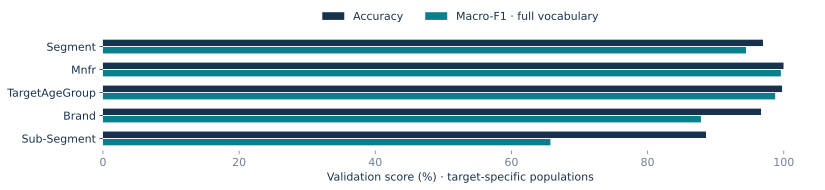

In [15]:
review.results()

**Read macro-F1 carefully:** full-vocabulary averaging retains every training class, including zero-validation-support classes. Brand has five such classes; Sub-Segment has two. The harness’s observed-label convention gives different values for the same predictions.

**These rows describe different tasks and eligible populations.** They are not a single cross-target ranking or protected-test result.

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 65s:** Lead with completion, then emphasize the accuracy–macro-F1 gaps in Brand and Sub-Segment. Show both averaging conventions instead of silently improving the headline by dropping unsupported classes. Missing target labels were excluded only from the supervised view. There are 59,569 target-record predictions across these five exports, not 59,569 unique products.

<small>Evidence: [Export verification and metric conventions](../docs/findings/03_modeling/14_minilm_prediction_exports.md), `minilm_validation_exports_v1/{segment,mnfr,targetagegroup,brand,sub_segment}/`.</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 10 of 14</div>

## Strong overall scores still leave weak classes

**Per-class checks prevent misleading conclusions from majority-heavy populations.** Selected examples below are recalculated from existing predictions.

In [16]:
review.weak_classes()

Target,Class,Validation n,Precision,Recall,F1
Mnfr,J&J,238,98.75%,99.58%,99.16%
TargetAgeGroup,Infant,138,99.26%,97.83%,98.54%
TargetAgeGroup,Children,572,97.57%,98.08%,97.82%
Sub-Segment,External Upper Respiratory,23,100.00%,8.70%,16.00%
Sub-Segment,Other Allergy,130,71.28%,51.54%,59.82%
Sub-Segment,Temperature Packs,65,75.00%,50.77%,60.55%
Brand,Astepro,13,0.00%,0.00%,0.00%


**Sub-Segment is the clearest remaining modeling weakness:** 88.58% accuracy coexists with 65.73% full-vocabulary macro-F1. External Upper Respiratory recall is only **2/23**.

Brand’s five training-only classes and Sub-Segment’s two training-only classes cannot establish held-out class performance. Tiny supported classes also have unstable estimates.

**Why stop before extra training:** more experiments would not resolve absent labels, taxonomy ambiguity or the need for independent comparison within this sprint review.

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 50s:** J&J performance counters the concern that Mnfr merely predicts All others. For Sub-Segment, good precision can accompany very poor recall. Brand’s Astepro misses show that the neural model is not uniformly strong on named brands. Do not infer that any of these probabilities supports an operational threshold.

<small>Evidence: [Remaining-target class limitations](../docs/findings/03_modeling/13_remaining_minilm_training_20261029.md), [allocation support](../docs/findings/03_modeling/04_target_development_allocation_20261029.md), recomputed per-class prediction metrics.</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 11 of 14</div>

## Brand normalization: the lookup remains a serious contender

**Fair comparison:** same 58,888 labeled training records, same 12,619 validation records, all catch-all labels and unseen/missing raw brands retained.

The deterministic lookup normalizes raw ProductBrand and uses the most frequent **training** label per key. Missing/unseen keys fall back to the training-majority class, `UnItemised brand`.

In [17]:
review.brand()

Method,Accuracy,Macro-F1 · all 143,Macro-F1 · supported 138
MiniLM,96.664%,87.834%,91.017%
Deterministic lookup + fallback,95.649%,93.119%,96.493%
Probabilistic lookup (fixed α=1),95.689%,93.111%,96.485%


Lookup cohort,Records,Deterministic accuracy,Probabilistic accuracy
Seen keys,10454,97.60%,97.65%
Unseen keys,2163,86.22%,86.22%
Missing ProductBrand,2,100.00%,100.00%
All fallback (subtotal),2165,86.24%,86.24%


**Tradeoff:** MiniLM has higher accuracy; the lookup has higher macro-F1. MiniLM handles `Other Brands` better (recall 63.43% versus 18.80% for the deterministic lookup). Choice depends on the business priority.

**Probabilistic lookup:** fixed α=1 training-prior smoothing supplies a full distribution. It changes only 17 decisions (11 corrections, six regressions); it is not calibrated. Seen-key coverage is **82.84%**, and headline scores include the fallback population.

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 65s:** The raw brand is authorized at inference, so overlap with curated Brand is part of the normalization task. Lookup’s macro-F1 advantage does not mean it handles the two catch-all labels better. The smoothing parameter was fixed before validation; the small accuracy increase is not a reason to declare a new winner. No hybrid was built.

<small>Evidence: [Original Brand comparison](../docs/findings/03_modeling/13_remaining_minilm_training_20261029.md), [probabilistic lookup](../docs/findings/03_modeling/15_brand_probabilistic_lookup.md), existing lookup/model evaluation JSON and probability export.</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 12 of 14</div>

## Retailer transfer: familiar-mix validation is not production proof

**Completed diagnostic:** train a separate Segment model on all 43,969 Amazon training records; evaluate the same original validation endpoints. Category representation, seed and fixed three-epoch schedule are retained.

Training population,Same non-Amazon validation n,Accuracy,Macro-F1
Mixed retailers (reference),2511,94.46%,89.92%
Amazon only,2511,87.10%,77.96%


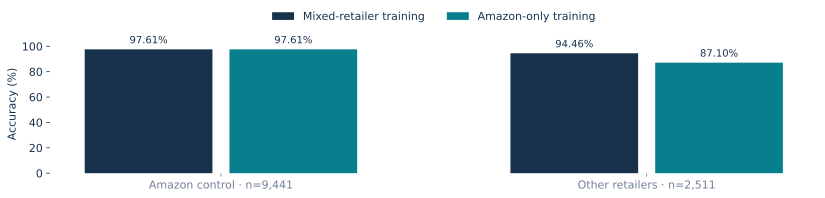

In [18]:
review.transfer_chart()

On the **same 2,511 other-retailer records**, accuracy drops **7.37 percentage points**. The saved paired group-bootstrap 95% interval for the gap is **5.57–9.44 points**.

**Interpretation:** transfer is weaker. Training volume, assortment, class mix and wording also changed, so this experiment does not isolate category dependence as the cause. It uses one training seed and no protected-test scoring.

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 50s:** Compare 94.46% with 87.10%, not the overall 96.95% score with the retailer endpoint. The Amazon control is 97.61% for both models. This is the appropriate place to qualify claims about new retailers, rather than hiding that concern after the headline result.

<small>Evidence: [Retailer-transfer findings](../docs/references/research/catalogiq_modeling_findings.md), `segment_retailer_holdout_category_20261010/validation_metrics.csv` and `paired_differences.csv`.</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 13 of 14</div>

## What the remaining errors look like

**Real validation products, joined by record ID from approved development data.** Titles are shortened for readability; full record IDs are in the verification appendix.

In [19]:
review.examples()

Target / ID prefix,Real validation product (title excerpt),Supplied label,MiniLM,Uncalibrated confidence
Segment · 06d2ca1299,Jarrow Formulas Fem-Dophilus - 5 Billion Organisms Per Serving - 60 Veggie Capsules - Women’s P…,Digestive Health,"Vitamins, Minerals & Supplements",79.5%
Sub-Segment · 11a8bd38c1,"Vicks VapoInhaler, On-the-Go Portable Nasal Inhaler, Non-Medicated, 1 Scented Stick",External Upper Respiratory,Allergy INS,58.7%
Brand · 0b29472b27,Astepro Allergy Azelastine Hydrochloride Steroid Free Antihistamine Nasal Spray - 120 Metered S…,Astepro,UnItemised brand,96.8%


- **Jarrow probiotic:** retailer breadcrumb includes supplements; supplied Segment is Digestive Health. The example motivates a taxonomy-boundary discussion rather than automatic relabeling.
- **Vicks inhaler:** External Upper Respiratory predicted as Allergy INS illustrates a weak fine-grained boundary.
- **Astepro:** a named brand is missed despite high softmax confidence. Confidence alone does not establish correctness or reviewability.

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 55s:** These are deliberately selected discussion examples, not a random error audit. Distinguish disagreement with the supplied label from proof that the supplied label is wrong. The model’s confidence is uncalibrated. No protected products were inspected to choose these examples.

<small>Evidence: Existing target validation `predictions.csv` files; product titles and category context from frozen `train.csv` / `validation.csv` only. Full IDs retained in Appendix B.</small>

</details>

<div class="cq-kicker">CatalogIQ / Sprint review / 14 of 14</div>

## Evaluation handoff and Ravi’s next decisions

| Status | What it means now |
|---|---|
| **Complete** | Current cleaning validation, frozen group controls, classical Segment baseline, five trained MiniLM candidates, Brand lookup comparisons, saved validation exports |
| **Complete: compatibility checks** | Exact target populations, class ordering, IDs, probabilities and Maria’s unchanged loader/headline scoring verified; no dropped rows |
| **Ongoing: Maria’s final comparative evaluation** | Cross-target comparison, minority-class/error analysis, calibration and review-policy assessment are not claimed complete |
| **Remaining** | Agree selection criteria and review capacity; investigate taxonomy boundaries; assess rare-class support; measure comparable inference latency; evaluate Platform with simpler methods |
| **Reserved** | Final protected-test evaluation after the model and evaluation procedure are selected; deployment remains future work |

**Handoff discipline:** use one target context at a time. Brand and Sub-Segment require their approved allocations; do not bypass split guards or combine different targets into one comparison.

**Model selection remains open:** compare MiniLM, the applicable classical baselines and lookup methods against business priorities. A different method may be appropriate for each target.

**Decisions for Ravi:** which matters most for Brand—overall accuracy, balanced named-class performance, or catch-all handling? What human-review load is affordable? How should retailer-versus-curated taxonomy conflicts be resolved?

**Measure the business benefit next:** share of listings safely accepted without manual classification, error rate among accepted predictions, and reviewer workload/time. These are proposed operating measures, not completed results.

<div class="cq-callout"><b>Ready for the next evaluation step:</b> use the saved predictions to compare candidates. Additional training is not needed to conduct that review.</div>

<details class="cq-presenter-notes">
<summary>Original presenter notes</summary>

> **Presenter notes · 55s:** End with the concrete handoff and decisions. Maria already owns a reusable harness and has performed Segment analyses; the new five-target export checks do not substitute for her final comparative review. Probability diagnostics and any temperature fit on the same validation set are not independent calibration evidence. We have not selected a production winner or scored the protected test.

<small>Evidence: [Five-target handoff](../docs/findings/03_modeling/14_minilm_prediction_exports.md), [lookup limits](../docs/findings/03_modeling/15_brand_probabilistic_lookup.md), [current handoff instructions](../data/processed/minilm_validation_exports_v1/HANDOFF_MARIA.md).</small>

</details>

<div class="cq-kicker">Optional appendix / A</div>

## Execution and environment

The core presentation is complete above. Saved outputs can be reviewed without executing code. Rerunning uses CPU-only pandas/NumPy/scikit-learn calculations and Matplotlib charts; it does not load neural weights.

From the repository root, use Python 3.11+ with the project’s notebook dependencies plus `matplotlib`, `nbformat`, `nbclient` and `nbconvert`. These were already available in the existing local Python 3.13 environment used for this delivery. The GPU training environment is not required.

```powershell
python -m jupyterlab notebooks/11_catalogiq_capstone_sprint_review.ipynb
```

Select an environment containing those packages. **Run All** works from the repository root or `notebooks/`. The small [presentation helper](catalogiq_review_support.py) must remain next to the notebook. Code cells are collapsed and tagged `hide-input`; they can be expanded for inspection.

Private local artifacts are required for re-execution: the frozen development train/validation exports and ID-only registry; approved Brand/Sub-Segment assignments; six validation prediction directories (five MiniLM plus probability lookup); the current cleaning validation/change log; Brand lookup results; Segment ablation and retailer-transfer results; the saved equality audit. Missing files raise a clear error; there is no replacement split generation or silent synthetic-data fallback.

The companion HTML is a static, code-hidden presentation with embedded charts and does not require a live kernel. Presenter notes are Markdown blockquotes in the notebook; slide metadata also marks them as notes.

<div class="cq-kicker">Optional appendix / B</div>

## Verification and reproducibility boundaries

The notebook checks manifest seals for consumed prediction/context/mapping/compatibility files, reconstructs the correct validation population from approved assignments, compares labels against development-only records, checks protected IDs/groups, and recomputes accuracy and both macro-F1 conventions. Probability columns are checked in numeric class order, including all 143 Brand classes.

All consumed evidence files are rehashed after rendering. The helper has a fixed file allowlist and no artifact-write path. `data/provided/`, neural checkpoints and `test.csv` are excluded. Only the protected registry’s identity columns are read. Original model training and prior integrity audits are documented evidence rather than newly rerun experiments.

In [20]:
verification = review.verify_unchanged()
table(__import__('pandas').DataFrame([
    {'Check': 'End-to-end evidence checks', 'Result': verification['status']},
    {'Check': 'Existing MiniLM target-record predictions recomputed',
     'Result': str(verification['minilm_target_rows_recomputed'])},
    {'Check': 'Existing probabilistic lookup predictions recomputed',
     'Result': str(verification['probabilistic_lookup_rows_recomputed'])},
    {'Check': 'Consumed source/artifact files unchanged',
     'Result': str(verification['consumed_files_unchanged'])},
    {'Check': 'Protected ID/group overlap', 'Result': '0'},
    {'Check': 'Training / inference / test.csv access', 'Result': 'None'},
]))
table(__import__('pandas').DataFrame(review.example_ids))

Check,Result
End-to-end evidence checks,passed
Existing MiniLM target-record predictions recomputed,59569
Existing probabilistic lookup predictions recomputed,12619
Consumed source/artifact files unchanged,46
Protected ID/group overlap,0
Training / inference / test.csv access,None


target,record_id
Segment,06d2ca12999a801a09e50c57c1d86d38aeb17aa4a46e419dcbee516450bc63b0
Sub-Segment,11a8bd38c1a4503ab677d6c0d9f7e74e218d2de8916c6a68ba53a3be2f502b07
Brand,0b29472b272d97f20a4a6b7946f4da188695911a3b1d5a685801dc006bbb4f9f


**What could not be independently verified in this delivery**

- Official sprint dates and numbered sprint assignments: absent from repository evidence; later progress is shown as dated phases.
- Max’s original classical prediction files: absent locally. The presentation uses the committed verified result report; it does not claim a new independent classical rescore. Maria’s existing branch documents her separate checks of those packaged arms.
- Maria’s final five-target comparative evaluation: no completed final report is established by these artifacts. Loader/headline checks and prior Segment analysis are narrower accomplishments.
- Production savings, live-request latency, independent probability calibration and performance on future retailers: not established. Saved batch throughput is not single-request latency.
- Bitwise retraining across machines: not rerun; one-seed results and historical environment limitations apply.

**Verified and available:** all five selected MiniLM prediction metrics and the probabilistic lookup metric; Brand deterministic aggregate agreement with its saved reproduction; exact validation membership/labels; class order/probabilities; development/protected group isolation; real cleaning examples and current partition counts.

<div class="cq-kicker">Optional appendix / C</div>

## Contribution evidence and historical authority

| Contributor | Repository evidence used for attribution |
|---|---|
| Sebastian | `251274d` profile; `639e009` target cleaner; `9010a63` structural/integrated exports; `cd5296a` group-aware split finalization; `c666867` MiniLM reproducibility; `128d9c7` target-aware training and evaluation exports |
| Max / Maksim (`heyitsmaks`) | `49c0da0` feature checks; `879a326` feature decisions; `505d309` cleaning integration; `a8fb9d1` word TF-IDF/category comparison; `77a002e` authoritative-split validation; `09df407` evaluation handoff |
| Maria (`mariagarciasehara`) | Relationship/evaluation research; branch commits `72502a2` full cleaning audit, `86d632e` feature-engineering research, `cb8e6e2` evaluation harness, `fc14be1` split guards, `05e52e2` scoring Max’s packaged arms and correcting stand-in comparisons |

Maria’s branch evidence was inspected through existing local Git objects. The [shared export findings](../docs/findings/03_modeling/14_minilm_prediction_exports.md) independently pin the actual harness at commit `05e52e2e0203dee6d58dfc2d0e72d513eed9ad95`; this notebook does not require branch checkout or a network request.

**Authority order:** current decisions + dated completed findings + sealed artifacts supersede old exploratory hypotheses. The root README’s “Segment model development” heading is older than the latest five-target findings. Historical notebooks involving Brand-to-J&J fills or a strict taxonomy tree are not current policy.

Useful paths:

- [Cleaning decision log](../docs/decisions.md) and [current policy validation](../docs/findings/01_cleaning/05_current_policy_validation.md).
- [Split finalization](../docs/findings/02_splitting/02_finalization_20261009.md) and [portable workflow](../docs/findings/02_splitting/03_portable_workflow_20261010.md).
- [Classical Segment results](../docs/findings/03_modeling/02_classical_segment_results_20261010.md).
- [MiniLM reproducibility](../docs/findings/03_modeling/01_minilm_256_reproducibility_20261015.md) and [representation equality audit](../docs/findings/03_modeling/02_minilm_256_equality_audit_20261015.md).
- [Mnfr selection](../docs/findings/03_modeling/11_mnfr_minilm_selection_20261029.md), [three remaining targets](../docs/findings/03_modeling/13_remaining_minilm_training_20261029.md), [five prediction exports](../docs/findings/03_modeling/14_minilm_prediction_exports.md), [Brand probability lookup](../docs/findings/03_modeling/15_brand_probabilistic_lookup.md).

The validation JSON beside this notebook records execution, runtime versions, the read-evidence hashes and the limitations above. No merge is performed as part of this presentation delivery.